**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

 Missing values per column (original dataset)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
 Missing values per column (cleaned dataset)
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
Normalized Features (First 5 rows)
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0       -0.896042       0.780732          -1.426752    -0.568475
1       -0.822788       0.119584          -1.069474    -0.506286
2       -0.676280       0.424729          -0.426373    -1.190361
4       -1.335566       1.085877          -0.569284    -0.941606
5       -0.859415       1.747026          -0.783651    -0.692852
 Predicted Cluster Labels
[0 0 0 0 0 0 0 0 0 0]
Cluster counts:
0    129
1    119
2     85
Name: count, dtype: int64


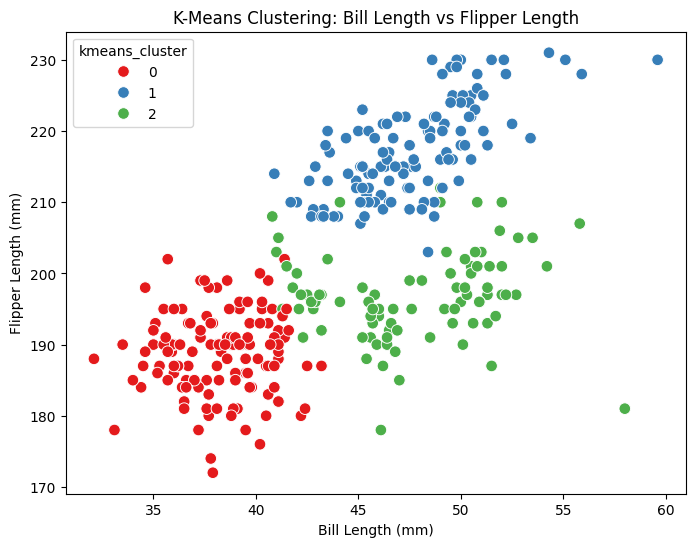

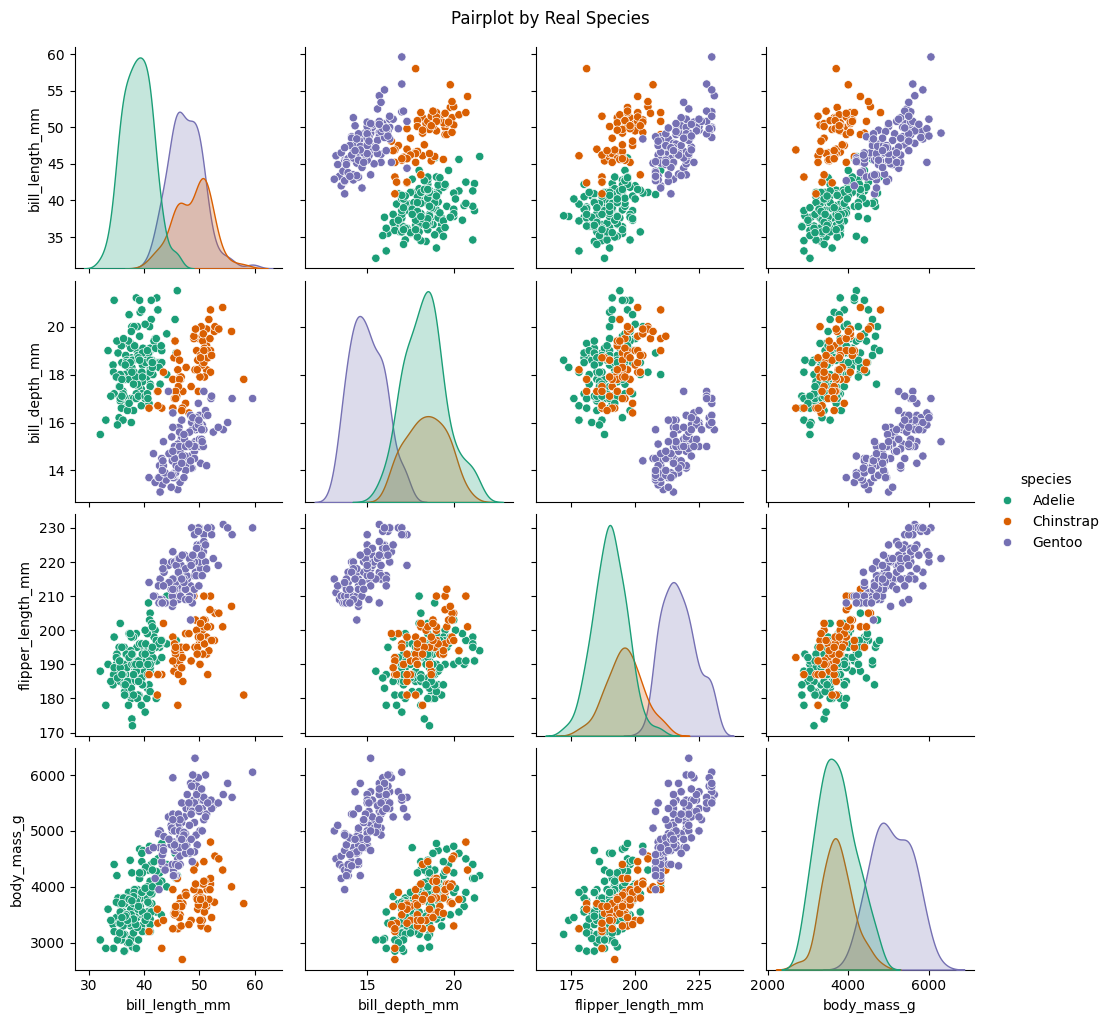

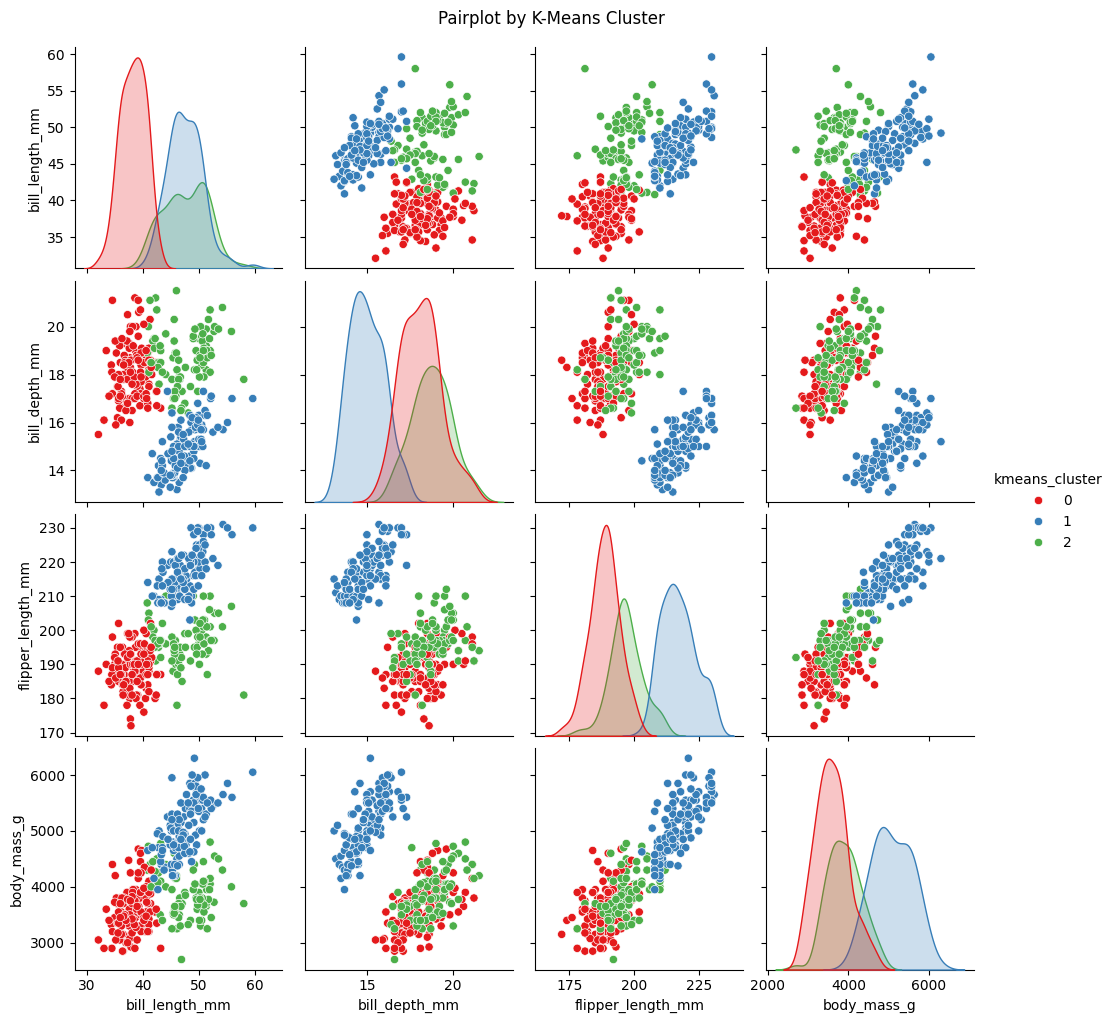

Confusion Matrix (Real Species vs K-Means Cluster)
K-Means Cluster    0    1   2
Real Species                 
Adelie           124    0  22
Chinstrap          5    0  63
Gentoo             0  119   0

Adjusted Rand Score (ARI): 0.7994


In [9]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

#això es per cargar el document
penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
# Check missing values per column in the original dataset
print(" Missing values per column (original dataset)")
print(penguins.isna().sum())

# Drop rows containing missing values (NaN), clean the Nan columns
penguins_clean = penguins.dropna().copy()

# Confirm that penguins_clean has no missing values left
print(" Missing values per column (cleaned dataset)")
print(penguins_clean.isna().sum())


# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
# Initialize the StandardScaler, makes the numbers all the same for the algorythm
scaler = StandardScaler()

# Fit and transform the numerical features
scaled_array = scaler.fit_transform(penguins_clean[num_cols])

# Save the result as a DataFrame with original column names and index
penguins_scaled_df = pd.DataFrame(
    scaled_array, columns=num_cols, index=penguins_clean.index)

# Display of first 5 rows to verify the normalized values
print("Normalized Features (First 5 rows)")
print(penguins_scaled_df.head())


# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
# Initialize the KMeans model with 3 clusters, becasue we know that we have 3 species of penguins
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

#  Fit the model on the scaled DataFrame and obtain cluster labels
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# Add the predicted cluster labels back to penguins_clean for later comparison
penguins_clean['cluster'] = kmeans_labels

# Display the first 10 predicted cluster labels
print(" Predicted Cluster Labels")
print(kmeans_labels[:10])
print("Cluster counts:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
# Add kmeans_labels to penguins_clean
penguins_clean['kmeans_cluster'] = kmeans_labels

#  Scatterplot: bill_length_mm vs flipper_length_mm colored by K-Means cluster
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='kmeans_cluster',
    palette='Set1',
    s=70
)
plt.title('K-Means Clustering: Bill Length vs Flipper Length')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.show()

#  Pairplot 1: Colored by real species
sns.pairplot(penguins_clean, vars=num_cols, hue='species', palette='Dark2')
plt.suptitle('Pairplot by Real Species', y=1.02)
plt.show()

#  Pairplot 2: Colored by predicted K-Means cluster
sns.pairplot(penguins_clean, vars=num_cols, hue='kmeans_cluster', palette='Set1')
plt.suptitle('Pairplot by K-Means Cluster', y=1.02)
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
# Compute and display the confusion matrix using pandas crosstab
conf_matrix = pd.crosstab(
    penguins_clean['species'],
    penguins_clean['kmeans_cluster'],
    rownames=['Real Species'],
    colnames=['K-Means Cluster']
)

print("Confusion Matrix (Real Species vs K-Means Cluster)")
print(conf_matrix)

# Calculate the Adjusted Rand Score (ARI)
ari_score = adjusted_rand_score(penguins_clean['species'], penguins_clean['kmeans_cluster'])
print(f"\nAdjusted Rand Score (ARI): {ari_score:.4f}")

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
# 1. K-means recovers the 3 species well with an ARI of 0.79.
# 2. Gentoo is 100% perfectly separated (119/119 in its own cluster).
# 3. Adelie and Chinstrap show some overlap in two clusters due to similar size.



---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Are there missing values (NaN) in X?: False
Normalized matrix X:
[[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
Custom Euclidean distance: 5.656854249492381
NumPy Euclidean distance:  5.656854249492381


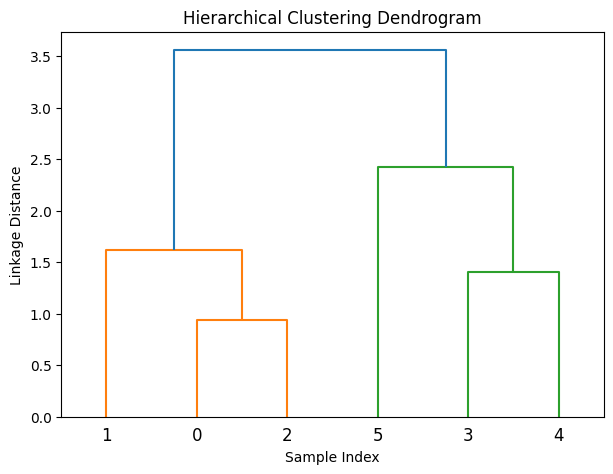

K-Means cluster labels:
[0 0 0 1 1 1]
Agglomerative Clustering labels: [1 1 1 0 0 0]
K-Means Clustering labels:       [0 0 0 1 1 1]


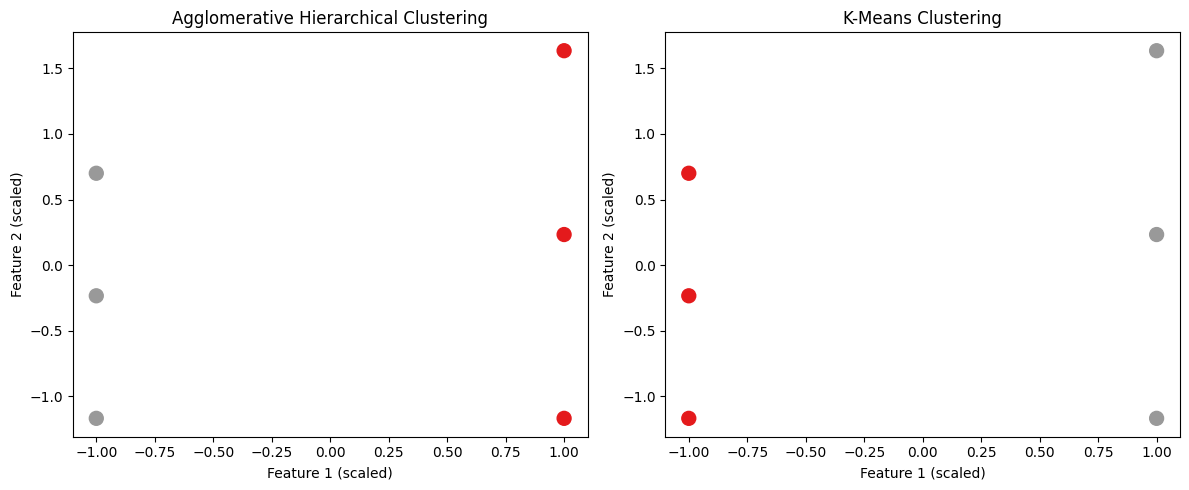

Agglomerative cluster sizes: {np.int64(1): 3, np.int64(0): 3}
K-Means cluster sizes:       {np.int32(0): 3, np.int32(1): 3}


In [15]:
import numpy as np
import math
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Matrix that we will use
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
has_missing_values = np.isnan(X).any()
print("Are there missing values (NaN) in X?:", has_missing_values)
# Returns False because all values are valid numbers, so we can proceed without prior cleaning

# b) YOUR CODE HERE: normalize X with StandardScaler
# StandardScaler is used because different features in X may have different scales or ranges, which would affect clustering results.
# StandardScaler standardizes the features (mean = 0, std = 1) to put everything on the same scale. X_scaled is the resulting normalized matrix.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Normalized matrix X:")
print(X_scaled)


# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)


def euclidean_distance(p1, p2):
    total_sum = 0.0
    for i in range(len(p1)):
        diff = p1[i] - p2[i]
        total_sum += diff ** 2
    return math.sqrt(total_sum)
    # Need to import math to use math.sqrt()

# Test the custom function and compare with NumPy's linalg.norm
print("Custom Euclidean distance:", euclidean_distance(X[0], X[3]))
print("NumPy Euclidean distance: ", np.linalg.norm(X[0] - X[3]))


# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
# Fit Agglomerative Hierarchical Clustering model with 2 clusters
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

# Compute the linkage matrix using Ward's method, What is Ward's method?
linked = linkage(X_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(7, 5))
dendrogram(linked)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Linkage Distance')
plt.show()


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
# n_clusters=2 specifies dividing the data into 2 groups, and random_state fixes the random seed.
#Comprovation
print("K-Means cluster labels:")
print(kmeans_labels)


# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot

#Difficult to understand

# Compare the predicted label arrays from both algorithms
print("Agglomerative Clustering labels:", agglo_labels)
print("K-Means Clustering labels:      ", kmeans_labels)

# Create a figure with 2 subplots side-by-side (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Agglomerative Hierarchical Clustering (Left plot)
axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=agglo_labels, cmap='Set1', s=100)
axes[0].set_title('Agglomerative Hierarchical Clustering')
axes[0].set_xlabel('Feature 1 (scaled)')
axes[0].set_ylabel('Feature 2 (scaled)')

# Subplot 2: K-Means Clustering (Right plot)
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap='Set1', s=100)
axes[1].set_title('K-Means Clustering')
axes[1].set_xlabel('Feature 1 (scaled)')
axes[1].set_ylabel('Feature 2 (scaled)')

plt.tight_layout()
plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary

def cluster_sizes(labels):
    """
    Counts the number of elements in each cluster using a plain Python dictionary.
    """
    #WHY 3 COMAS??
    sizes = {}
    for label in labels:
        if label in sizes:
            sizes[label] += 1
        else:
            sizes[label] = 1
    return sizes

# Test the function on both agglomerative and k-means label arrays
print("Agglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-Means cluster sizes:      ", cluster_sizes(kmeans_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values per column
carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64
Are there any missing values left in the dataset?: False
Cleaned dataset shape: (1000, 7)


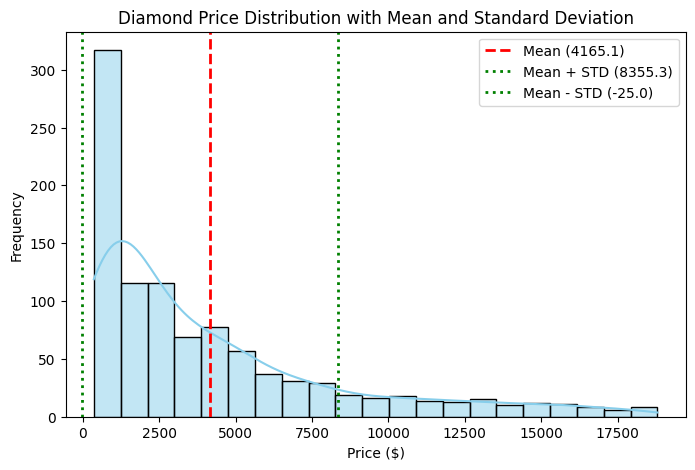

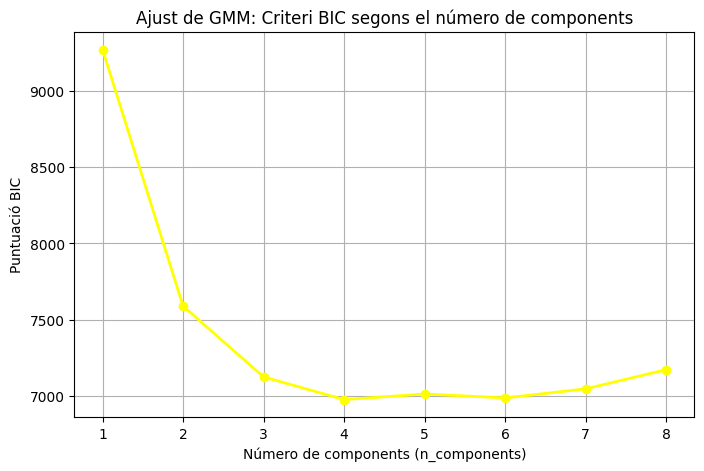

Nombre òptim de components (mínim BIC): 4
Primeres 10 etiquetes de cluster: [0 3 0 0 1 2 3 3 2 2]


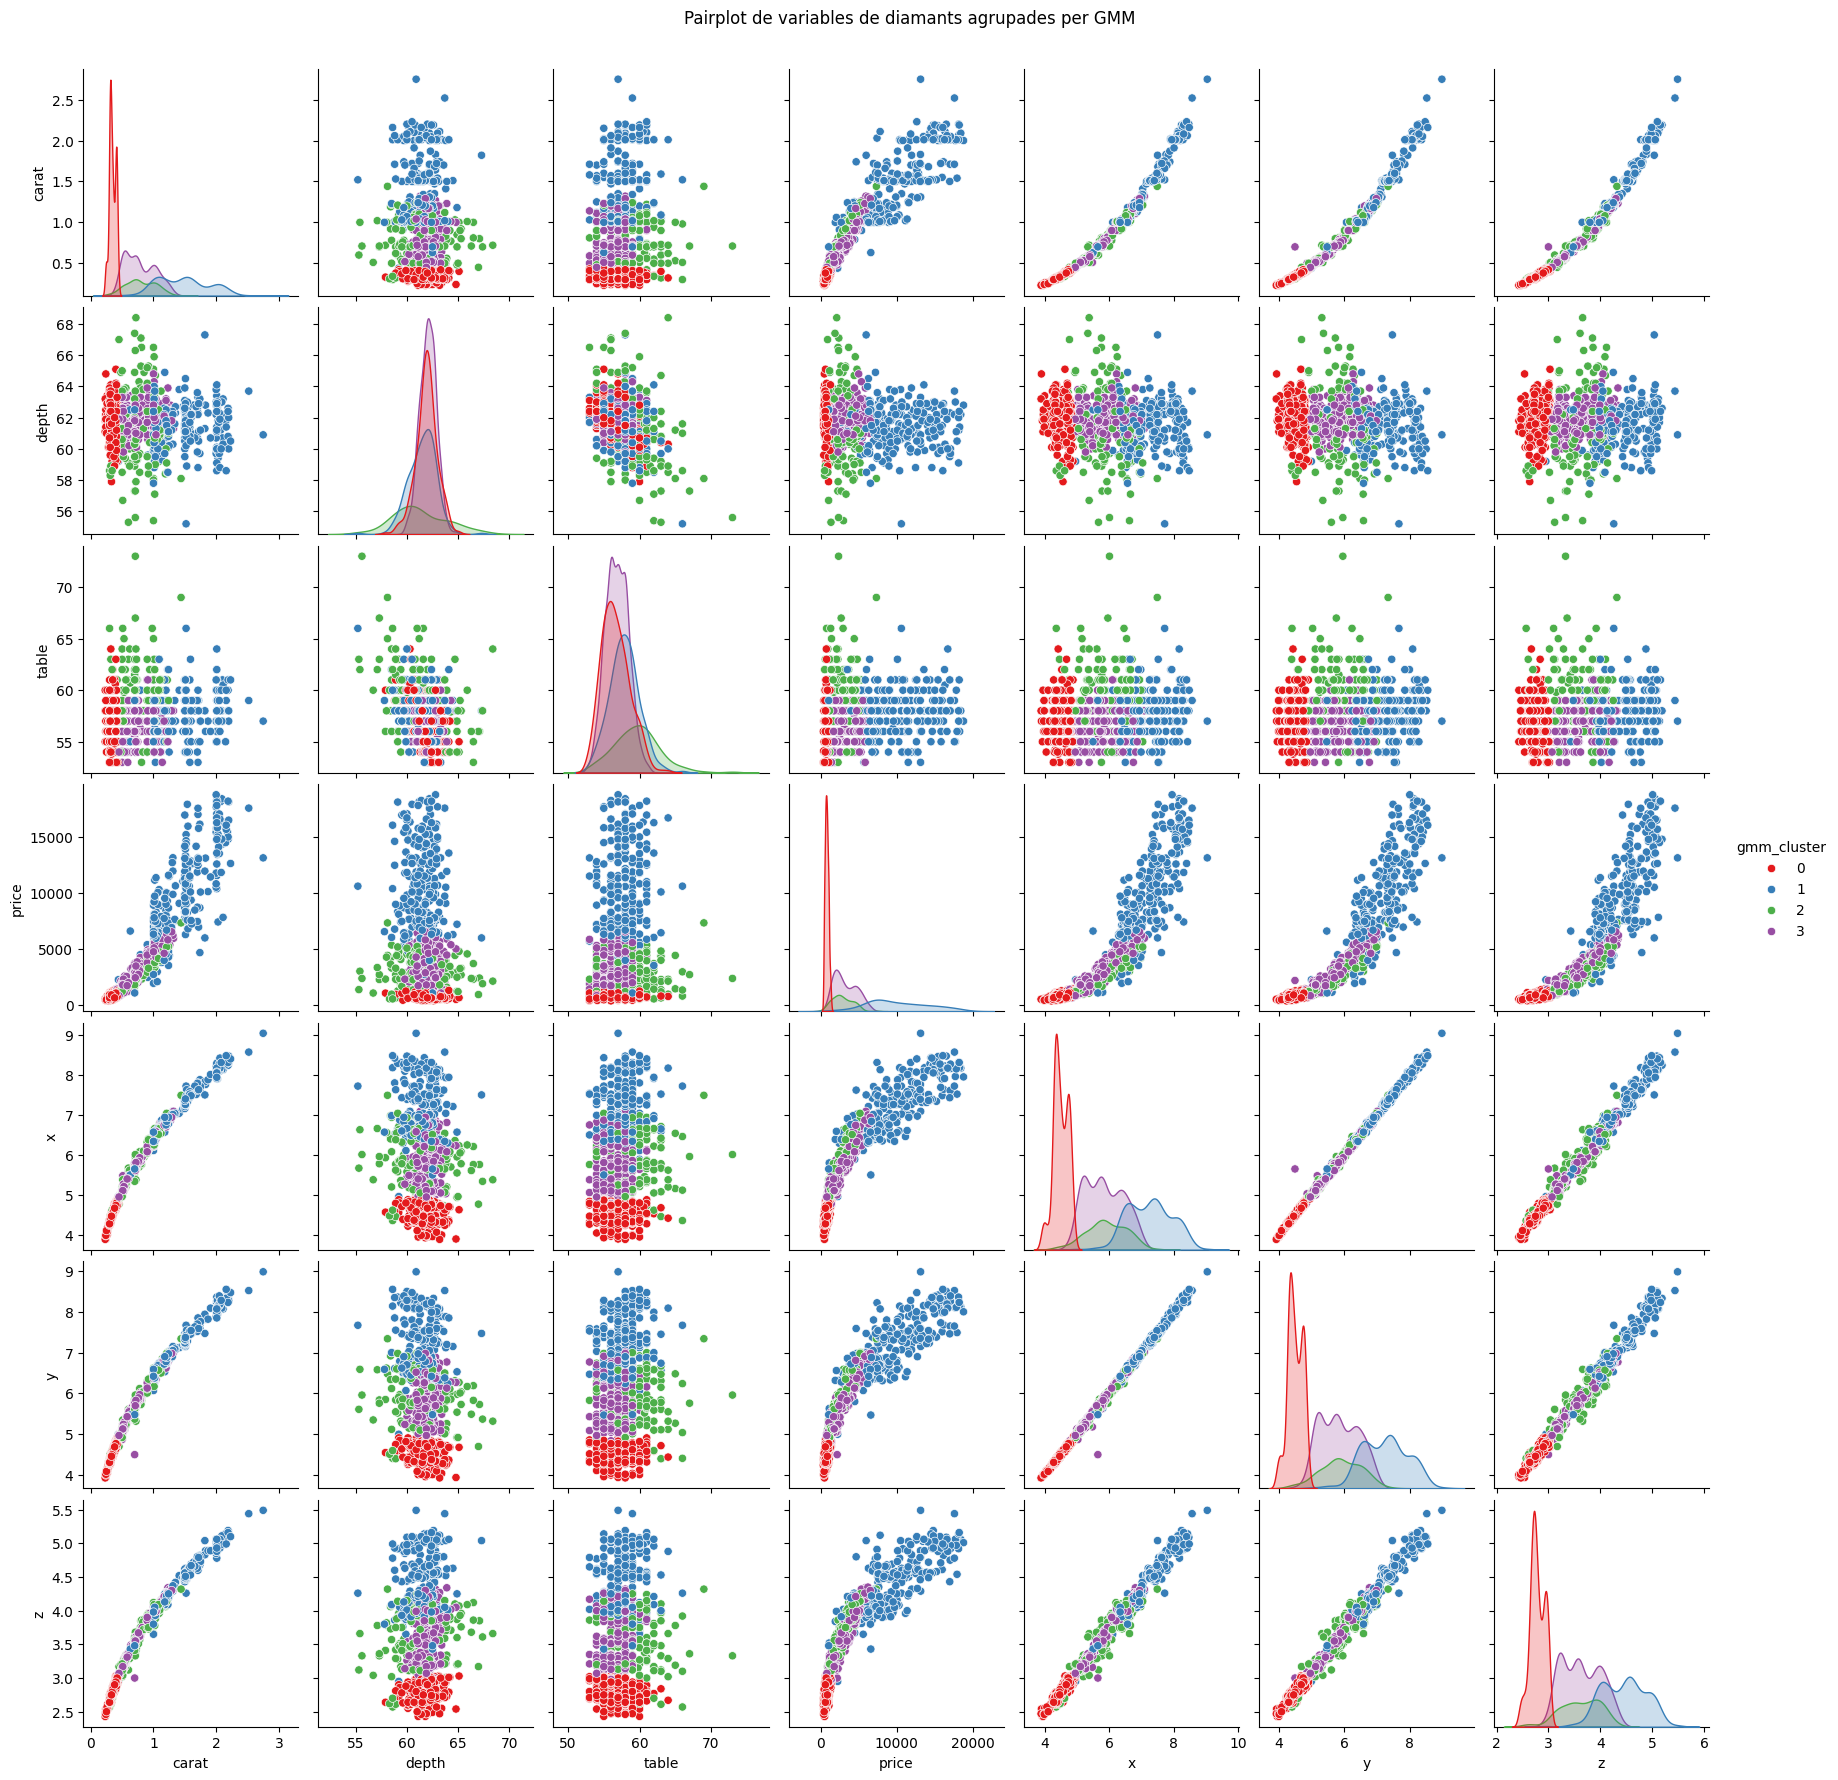

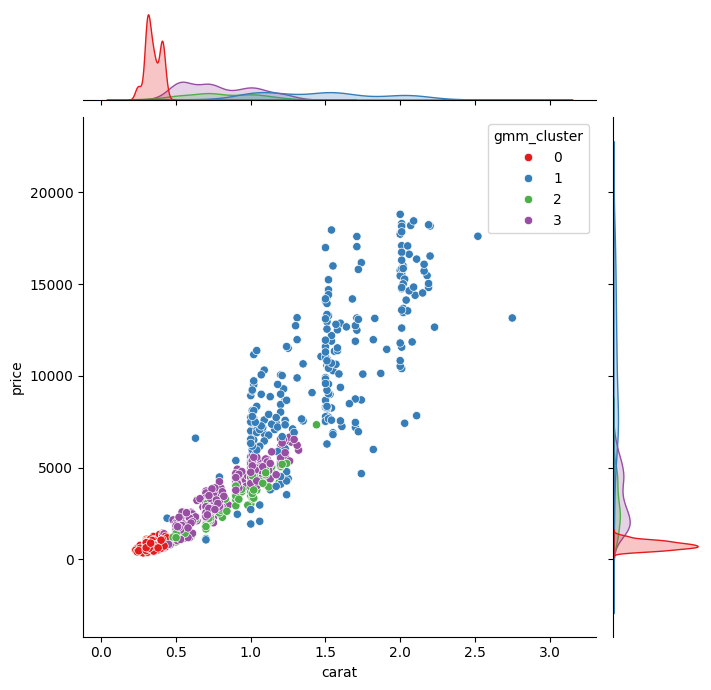

In [16]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean

diamonds_num = diamonds.select_dtypes(include=[np.number]).dropna().copy()

print("Missing values per column")
print(diamonds_num.isna().sum())

print("Are there any missing values left in the dataset?:", diamonds_num.isna().any().any())
print("Cleaned dataset shape:", diamonds_num.shape)


# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

#Calculation of the mean and standard deviation of 'price'
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

# Plot the price distribution histogram with KDE curve using Seaborn
plt.figure(figsize=(8, 5))
sns.histplot(diamonds_num['price'], kde=True, color='skyblue')

#  Drawing vertical reference lines for mean and mean +/- 1 standard deviation
plt.axvline(mean_price, color='red', linestyle='--', linewidth=2, label=f'Mean ({mean_price:.1f})')
plt.axvline(mean_price + std_price, color='green', linestyle=':', linewidth=2, label=f'Mean + STD ({mean_price + std_price:.1f})')
plt.axvline(mean_price - std_price, color='green', linestyle=':', linewidth=2, label=f'Mean - STD ({mean_price - std_price:.1f})')

# Customitzation of chart title, axis labels, and legend
plt.title('Diamond Price Distribution with Mean and Standard Deviation')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.legend()
plt.show()


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
# Selection of  the 4 main numeric features
cols_4 = ['carat', 'depth', 'table', 'price']

scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num[cols_4])


# From this point all is made with the use of IA, very difficult to understand what I did

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

# 1. Ajustem un model GMM per a cada n_components i guardem el BIC
for n in n_components_range:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

# 2. Dibuixem el gràfic de línia del BIC vs n_components
plt.figure(figsize=(8, 5))
plt.plot(n_components_range, bic, marker='o', color='yellow', linewidth=2)
plt.title('Ajust de GMM: Criteri BIC segons el número de components')
plt.xlabel('Número de components (n_components)')
plt.ylabel('Puntuació BIC')
plt.xticks(n_components_range)
plt.grid(True)
plt.show()

#A partir d'aqui tot ha sigut amb ajuda de la IA, díficl entendra-ho

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM

# 1. Find the number of components that minimizes the BIC score
best_n = n_components_range[np.argmin(bic)]

# 2. Fit the final GMM model with the optimal number of components
final_gmm = GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)

# 3. Print the results for verification
print("Optimal number of components (minimum BIC):", best_n)
print("First 10 cluster labels:", gmm_labels[:10])


# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)

# 1. Add GMM cluster labels to the original unscaled DataFrame
diamonds_num['gmm_cluster'] = gmm_labels

# 2. Generate a pairplot for all numeric variables colored by GMM cluster
sns.pairplot(diamonds_num, hue='gmm_cluster', palette='Set1')
plt.suptitle('Pairplot of Diamond Features Grouped by GMM Cluster', y=1.02)
plt.show()

# 3. Generate a jointplot specifically for 'carat' vs 'price'
sns.jointplot(
    data=diamonds_num,
    x='carat',
    y='price',
    hue='gmm_cluster',
    palette='Set1',
    height=7
)
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# I prefer to be at class for the interpretation, not clear about what I did from the starting paragraph e